# Matrix Calculus, Tensors, and Quadratic Forms

**AI Mathematics · 1. Linear Algebra**

Connect matrix derivatives, covariance structure, higher-dimensional tensors, and einsum notation to deep-learning computations.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Differentiate scalar losses with respect to vectors and matrices.
- Interpret Jacobians, Hessians, and quadratic forms.
- Operate on batched tensors and use einsum for contractions.

In [1]:
import numpy as np

## 1. Quadratic forms and positive definiteness
A quadratic form is \(x^TAx\). When \(A\) is symmetric positive definite, it is positive for every nonzero \(x\), and it defines a bowl-shaped quadratic objective. Covariance matrices are positive semidefinite by construction.

In [2]:
import numpy as np

A = np.array([[3.0, 1.0], [1.0, 2.0]])
x = np.array([2.0, -1.0])
print("x^T A x:", x @ A @ x)
print("eigenvalues:", np.linalg.eigvalsh(A))

rng = np.random.default_rng(7)
X = rng.normal(size=(100, 3))
cov = np.cov(X, rowvar=False)
print("covariance eigenvalues:", np.linalg.eigvalsh(cov))

x^T A x: 10.0
eigenvalues: [1.38196601 3.61803399]
covariance eigenvalues: [0.59614073 0.88192142 1.08800426]


## 2. Derivatives of common matrix expressions
For symmetric \(A\), \(f(x)=\frac12 x^TAx\) has gradient \(\nabla_x f=Ax\). More generally, if \(f(x)=\frac12 x^T(A+A^T)x\), the gradient is \(\frac12(A+A^T)x\). Shape conventions matter when differentiating matrices.

In [3]:
A = np.array([[3.0, 1.0], [0.0, 2.0]])
x = np.array([1.0, -2.0])
gradient = 0.5 * (A + A.T) @ x
print("gradient of 0.5*x^T A x:", gradient)

# For symmetric A, this reduces to A @ x.
S = (A + A.T) / 2
print("symmetric-form gradient:", S @ x)

gradient of 0.5*x^T A x: [ 2.  -3.5]
symmetric-form gradient: [ 2.  -3.5]


## 3. Jacobian and Hessian
For a function \(f:\mathbb{R}^n\to\mathbb{R}^m\), the Jacobian contains first derivatives and has shape \((m,n)\). For a scalar-valued function, the Hessian contains second derivatives and has shape \((n,n)\).

In [4]:
def f(z):
    x, y = z
    return np.array([x * y, x**2 + y])

def jacobian_central(func, x, eps=1e-6):
    x = np.asarray(x, dtype=float)
    base = np.atleast_1d(func(x))
    J = np.zeros((base.size, x.size))
    for j in range(x.size):
        step = np.zeros_like(x)
        step[j] = eps
        J[:, j] = (np.atleast_1d(func(x + step)) - np.atleast_1d(func(x - step))) / (2 * eps)
    return J

point = np.array([2.0, 3.0])
print(jacobian_central(f, point))  # expected [[3, 2], [4, 1]]

[[3. 2.]
 [4. 1.]]


## 4. Tensors and batch matrix multiplication
A tensor is an array with zero or more axes: scalar (0-D), vector (1-D), matrix (2-D), or higher-dimensional array. A common deep-learning convention is `(batch, sequence, features)`. Read shapes carefully before multiplying.

In [5]:
# Three 2x2 matrices: shape (batch=3, rows=2, columns=2)
A = np.arange(12.0).reshape(3, 2, 2)
B = np.broadcast_to(np.eye(2), (3, 2, 2))
C = A @ B
print("A shape:", A.shape)
print("batch multiplication shape:", C.shape)
print("unchanged by identity:", np.allclose(A, C))

A shape: (3, 2, 2)
batch multiplication shape: (3, 2, 2)
unchanged by identity: True


## 5. Einsum notation
`einsum` expresses sums over labeled dimensions. For example, `ij,jk->ik` is matrix multiplication, `bi,bi->b` computes one dot product per batch item, and `bqd,bkd->bqk` forms query-key scores over a batch. In attention, scores are usually scaled by \(1/\sqrt{d_k}\).

In [6]:
# Matrix multiplication with einsum
A = np.array([[1.0, 2.0], [3.0, 4.0]])
B = np.array([[2.0, 0.0], [1.0, 2.0]])
print(np.einsum("ij,jk->ik", A, B))

# Per-row dot products
X = np.array([[1.0, 2.0], [3.0, 4.0]])
Y = np.array([[5.0, 6.0], [7.0, 8.0]])
print(np.einsum("bi,bi->b", X, Y))

# Small attention score example: batch x query positions x feature dimension
Q = np.ones((2, 3, 4))
K = np.ones((2, 5, 4))
scores = np.einsum("bqd,bkd->bqk", Q, K) / np.sqrt(Q.shape[-1])
print("attention score shape:", scores.shape)  # (batch, queries, keys)

[[ 4.  4.]
 [10.  8.]]
[17. 53.]
attention score shape: (2, 3, 5)


## 6. Matrix gradients in learning
For linear regression with data matrix \(X\), targets \(y\), and parameters \(w\), a common objective is \(L(w)=\frac{1}{2n}\|Xw-y\|^2\). Its gradient is \(\nabla_w L=\frac{1}{n}X^T(Xw-y)\). This is a basic example of matrix calculus in model training.

In [7]:
X = np.array([[1.0, 0.0], [1.0, 1.0], [1.0, 2.0]])
y = np.array([1.0, 2.0, 2.5])
w = np.array([0.0, 0.0])
n = len(y)
error = X @ w - y
grad = X.T @ error / n
loss = (error @ error) / (2 * n)
print("loss:", loss)
print("gradient:", grad)

loss: 1.875
gradient: [-1.83333333 -2.33333333]


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: tensors, batches, and `einsum`

A tensor is an array with any number of axes. A batch of matrices has shape `(batch, rows, columns)`. `np.einsum` describes which axes are multiplied and which are retained; it is powerful, but labels should be chosen carefully because an incorrect label can silently compute a different operation.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_ten_A = np.arange(2*2*3, dtype=float).reshape(2, 2, 3)
viz_ten_B = np.ones((2, 3, 2))
viz_ten_standard = viz_ten_A @ viz_ten_B
viz_ten_einsum = np.einsum("bij,bjk->bik", viz_ten_A, viz_ten_B)
print("A shape:", viz_ten_A.shape, "B shape:", viz_ten_B.shape)
print("batched matmul shape:", viz_ten_standard.shape)
print("einsum agrees:", np.allclose(viz_ten_standard, viz_ten_einsum))
print("sum over the last axis:", np.einsum("bij->bi", viz_ten_A))
display(pd.DataFrame(viz_ten_A[0], columns=["feature 1", "feature 2", "feature 3"]))

A shape: (2, 2, 3) B shape: (2, 3, 2)
batched matmul shape: (2, 2, 2)
einsum agrees: True
sum over the last axis: [[ 3. 12.]
 [21. 30.]]


,feature 1,feature 2,feature 3
0,0.0,1.0,2.0
1,3.0,4.0,5.0


### Visualize a quadratic form

For a symmetric matrix \(A\), the scalar \(f(x)=x^T A x\) describes a quadratic surface. Its level sets are ellipses when \(A\) is positive definite. The gradient is \(
abla f(x)=2Ax\), so the gradient points toward increasing values and is perpendicular to a level curve.

05_matrix_calculus_tensors_and_quadratic_forms.ipynb:cell19:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
05_matrix_calculus_tensors_and_quadratic_forms.ipynb:cell19:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


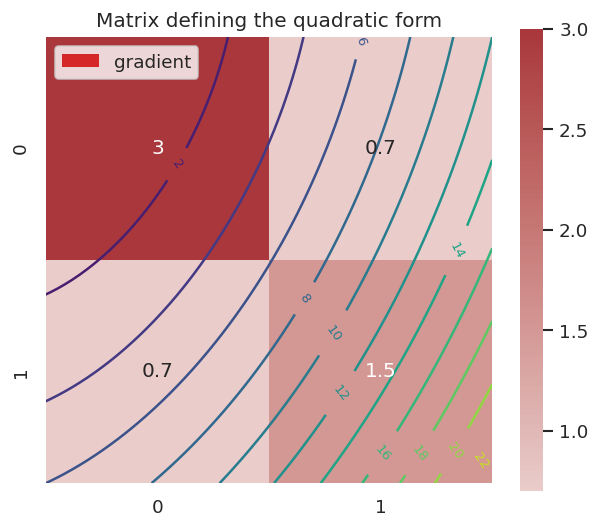

In [9]:
viz_quad_A = np.array([[3.0, 0.7], [0.7, 1.5]])
viz_quad_x = np.linspace(-2, 2, 120)
viz_quad_y = np.linspace(-2, 2, 120)
viz_quad_X, viz_quad_Y = np.meshgrid(viz_quad_x, viz_quad_y)
viz_quad_Z = viz_quad_A[0,0]*viz_quad_X**2 + 2*viz_quad_A[0,1]*viz_quad_X*viz_quad_Y + viz_quad_A[1,1]*viz_quad_Y**2
fig, ax = plt.subplots(figsize=(6, 5))
cs = ax.contour(viz_quad_X, viz_quad_Y, viz_quad_Z, levels=12, cmap="viridis")
ax.clabel(cs, inline=True, fontsize=8)
viz_quad_p = np.array([0.8, -0.6]); viz_quad_g = 2*viz_quad_A @ viz_quad_p
ax.quiver(viz_quad_p[0], viz_quad_p[1], viz_quad_g[0], viz_quad_g[1], angles="xy", scale_units="xy", scale=1, color="tab:red", label="gradient")
ax.set_aspect("equal", adjustable="box"); ax.legend(); ax.set_title("Quadratic-form contours and gradient"); plt.show()
sns.heatmap(viz_quad_A, annot=True, cmap="vlag", center=0)
plt.title("Matrix defining the quadratic form"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute batch dot products for two arrays with shape (4, 3).

In [10]:
A = np.arange(12.0).reshape(4, 3)
B = np.ones((4, 3))
print(np.einsum("bi,bi->b", A, B))

[ 3. 12. 21. 30.]


### Exercise 2
Exercise 2: Verify the gradient of 0.5*x^T A x for a symmetric matrix.

In [11]:
A = np.array([[2.0, 1.0], [1.0, 3.0]])
x = np.array([2.0, 4.0])
print("analytic:", A @ x)
print("symmetric:", np.allclose(A, A.T))

analytic: [ 8. 14.]
symmetric: True


## Key takeaways
- A Jacobian tracks how vector outputs change; a Hessian tracks second derivatives of a scalar objective.
- Tensors need explicit shape reasoning; einsum is a compact language for axis-wise products and sums.
- Quadratic forms and covariance matrices connect linear algebra to convexity and statistics.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.